In [1]:
%pip install -q otter-grader


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Case Study 20: Mapping a Volunteer Network for a Community Nonprofit

**DS701 — Session 23 (Mon Nov 23, 2026) — Section A1**

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tools4ds/DS701-Materials-FA26/blob/main/class_activity_notebooks/20-InClass-Exercise-Networks-I-A1/20-InClass-Exercise-Networks-I-A1.ipynb)

**Time: ~40 minutes.** Work in groups of 2-3.

Parts marked **(autograded)** are submitted to Gradescope; open-ended parts are graded
for participation. You may use AI assistance, but you must be able to explain and
justify every part of your solution when asked.

**Plan**

| Part | The nonprofit's question | Method | Grading | Time |
|---|---|---|---|---|
| 1 | Who works with whom? Can the whole log go in one table we can read? | Edge list to `nx.Graph`; the adjacency matrix; degree = row sums | autograded | ~8 min |
| 2 | Are we one community or several, and how far apart are people? | Components, shortest paths, diameter — real vs $G(n,p)$ | autograded | ~8 min |
| 3 | Are there a few hubs everyone works with, or is everyone similar? | Degree distributions: a heavy tail vs $G(n,p)$ on log–log axes | autograded | ~10 min |
| 4 | Do a volunteer's collaborators know each other? | Clustering coefficient: real vs random | autograded | ~5 min |
| — | Report out: what you would tell the nonprofit | team memo, then pair-share | participation | ~10 min |

Dependencies: `numpy`, `pandas`, `matplotlib`, `networkx`.


## Case Study Setup

You are the data scientist a **community-services nonprofit** has brought in for a
few weeks. Its volunteers staff a food pantry, a tutoring program and a weekend
repair crew; the coordinator keeps a shift log of who worked with whom, and nobody
has ever analysed it. The board has three questions: *who works with whom?*, *are our
volunteers one community or several?*, and *do a few people hold the whole thing
together — and what happens if they leave?* The answers decide where next year's
coordinator stipends go and whether the organization is ready to split into two
chapters (that decision is next session's case).

The shift log names real volunteers, and the board wants a privacy review before it
leaves the building. So you build the prototype on a public network of the same shape:
**Zachary's karate club** — 34 members of a real university karate club, recorded
in the early 1970s and published in 1977; an edge means two members interacted
outside the club, and its weight is how many times. It ships with NetworkX, so
nothing is downloaded. For the prototype, read each member as a **volunteer** and
each edge weight as **how often two volunteers worked a shift together**.

The raw data is an **edge list with a weight column** — `(u, v, w)` triples — and every
graph in this notebook is built from that list. In Parts 1–4 you ignore the weights
and work with the plain undirected, unweighted graph, exactly as the lecture treated
the football network. The weights come back at the report-out, where you decide
whether the nonprofit's questions need them.

**What the nonprofit asked you, and where you answer it**

1. *Who works with whom — and can the whole log be put in one table we can read?*
   — Part 1
2. *Are we one community or several, and how far apart are people, compared with a
   network where ties formed at random?* — Part 2
3. *Are there a few hubs everyone works with, or is everyone about the same — and
   how would we tell?* — Part 3
4. *Do a volunteer's collaborators know each other?* — Part 4
5. *Which version of the network — plain, weighted, or directed — do our questions
   actually need?* — Report out, from your Parts 1–4 results and lecture 20; no code.

The random networks you compare against in Parts 2–4 are fixed by the seed below.

Run the next four cells as-is — everything below depends on them.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx


In [3]:
# Lecture section. Only A1 runs this semester; this is kept because the build
# script reads it to name the variant directory the notebook is published in.
SECTION = "A1"
SEED = 701
rng = np.random.default_rng(SEED)

In [4]:
# Colab: fetch the autograder tests for this activity.
import os, sys, urllib.request

if "google.colab" in sys.modules:
    os.makedirs("tests", exist_ok=True)
    BASE = "https://raw.githubusercontent.com/tools4ds/DS701-Materials-FA26/main/class_activity_notebooks/20-InClass-Exercise-Networks-I-A1/tests/"
    for _q in ("q1", "q2", "q3", "q4"):
        urllib.request.urlretrieve(BASE + _q + ".py", "tests/" + _q + ".py")

In [5]:
# Initialize Otter
import otter
grader = otter.Notebook()

In [6]:
REAL_NAME = "Zachary's karate club"
_G0 = nx.karate_club_graph()

# The raw data: a node list and an edge list with a weight column.
nodes = sorted(_G0.nodes())
edge_list = [(u, v, int(d["weight"])) for u, v, d in _G0.edges(data=True)]
del _G0   # from here on, everything is built from `nodes` and `edge_list`

print(f"Section {SECTION}: {REAL_NAME}")
print(f"{len(nodes)} nodes, {len(edge_list)} edges")
print("first five edges (u, v, weight):", edge_list[:5])

Section A1: Zachary's karate club
34 nodes, 78 edges
first five edges (u, v, weight): [(0, 1, 4), (0, 2, 5), (0, 3, 3), (0, 4, 3), (0, 5, 3)]


## Part 1 (autograded): build the network from the log; the adjacency matrix *is* the network

**Why.** The coordinator's first question is simply *who works with whom* — and whether
the whole log can be put in one table she can read. It can. A graph is $G = (V, E)$;
in NetworkX: `G = nx.Graph()`, then `G.add_nodes_from(...)` and `G.add_edges_from(...)`
— for now **ignoring the weight column**. Once the volunteers are numbered, the same
information is the **adjacency matrix** $A$, with $A_{ij} = 1$ if $(i,j) \in E$ and $0$
otherwise, and everything the lecture read off $A$ applies: a volunteer's number of
collaborators is a **row sum**, the average degree is $2e/n$, the **density**
$e/\binom{n}{2}$ is the fraction of possible pairs that ever shared a shift, and
$(A^2)_{ij}$ counts the walks of length 2 — the collaborators $i$ and $j$ have in
common. `nx.to_numpy_array(G, nodelist=nodes)` builds $A$ in the node order you give.

**Task.**

1. Build `G`, an undirected `nx.Graph` with node set `nodes` and one edge per triple in
   `edge_list` (drop the weight).
2. Set `n_nodes`, `n_edges` (ints) and `avg_degree` (a float, $2e/n$).
3. Build `A`, the adjacency matrix as a NumPy array in the order of `nodes`.
4. Set `deg_from_A` to the row sums of `A` and `deg_from_G` to the degrees reported by
   `G.degree` **in the same node order**; set `degrees_match` to `True` if they agree.
5. Set `top_node` to the node with the largest degree and `max_degree` to that degree.


In [7]:
G = nx.Graph()
G.add_nodes_from(nodes)
G.add_edges_from((u, v) for u, v, _ in edge_list)   # drop the weight

n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()
avg_degree = 2 * n_edges / n_nodes

A = nx.to_numpy_array(G, nodelist=nodes)
deg_from_A = A.sum(axis=1)
deg_from_G = np.array([G.degree(v) for v in nodes])
degrees_match = bool(np.array_equal(deg_from_A, deg_from_G))

top_node = max(nodes, key=G.degree)
max_degree = G.degree(top_node)


print(f"{REAL_NAME}: n = {n_nodes}, e = {n_edges}, average degree = {avg_degree:.3f}")
print("A.shape =", A.shape, "| symmetric:", np.array_equal(A, A.T), "| degree = row sums:", degrees_match)
print(f"highest-degree node: {top_node!r} with degree {max_degree}")

Zachary's karate club: n = 34, e = 78, average degree = 4.588
A.shape = (34, 34) | symmetric: True | degree = row sums: True
highest-degree node: 33 with degree 17


In [8]:
grader.check("q1")

q1 results: All test cases passed!

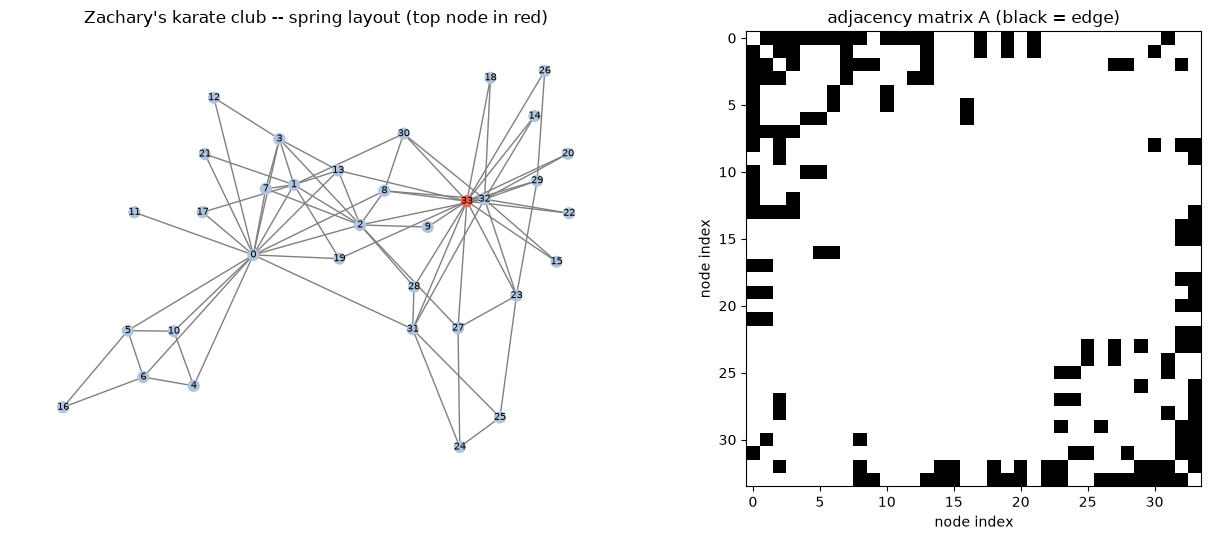

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
pos = nx.spring_layout(G, seed=SEED)
nx.draw_networkx(G, pos=pos, ax=axes[0], node_size=60, with_labels=(n_nodes <= 40), font_size=7,
                 node_color=["tomato" if v == top_node else "lightsteelblue" for v in G.nodes()], edge_color="gray")
axes[0].set_title(f"{REAL_NAME} -- spring layout (top node in red)"); axes[0].axis("off")
axes[1].imshow(A, cmap="Greys", interpolation="nearest")
axes[1].set_title("adjacency matrix A (black = edge)"); axes[1].set_xlabel("node index"); axes[1].set_ylabel("node index")
plt.tight_layout(); plt.show()

The picture on the left and the matrix on the right are **the same object** — the
table the coordinator asked for. Everything you compute in this notebook could be
computed from `A` alone: degree is a row sum; the density is `A.sum() / 2` over
$\binom{n}{2}$ (Part 4 needs it as `p_real`); and $(A^2)_{ij}$ counts the walks of
length 2 from $i$ to $j$, so for $i \ne j$ it is the number of collaborators the two
volunteers share. Next session's centrality measures are literally linear algebra on $A$.


## Part 2 (autograded): one community or several? components, paths, diameter — real vs $G(n,p)$

**Why.** The board's second question is whether the volunteers are *one community or
several*, and how far apart people are. In the lecture's terms: *is the graph
connected?* If not, what are the **connected components** and how big is the largest?
Then: **shortest paths**, and the **diameter** (the largest shortest-path length). A
number like "diameter 5" means nothing on its own, so you compare with a network where
ties form at random.

`ER` below is a $G(n,p)$ random graph with $n = 200$ and $p$ chosen so the average degree
is a little above 1 — deliberately sparse, so it falls apart: this is what a volunteer
base that is *not* one community looks like. Note the by-doing lesson waiting for
you: `nx.diameter` **raises an error on a disconnected graph** (the distance between two
components is infinite). You must ask about the *largest component* instead.

**Task.**

1. On the real graph `G`: `n_comp_real = nx.number_connected_components(G)`,
   `diam_real = nx.diameter(G)`, `aspl_real = nx.average_shortest_path_length(G)`.
2. Set `n_within_2` to the number of *other* nodes within **2 hops** of `top_node`
   (`nx.single_source_shortest_path_length` gives you the hop distances).
3. On `ER`: build `components`, the list of its connected components (each a `set` of
   nodes) **sorted largest first**; set `n_comp_er = len(components)`, `n_isolated_er` to
   the number of single-node components, `largest_er` to the subgraph of `ER` on the
   largest component (`ER.subgraph(...)`), `size_largest_er` to its number of nodes, and
   `diam_largest_er = nx.diameter(largest_er)`.


In [10]:
N_ER = 200
P_ER = 1.6 / (N_ER - 1)   # average degree ~1.6 / ~1.4
ER = nx.erdos_renyi_graph(N_ER, P_ER, seed=SEED)
print(f"ER: n = {N_ER}, e = {ER.number_of_edges()}, average degree = {2 * ER.number_of_edges() / N_ER:.2f}")

n_comp_real = nx.number_connected_components(G)
diam_real = nx.diameter(G)
aspl_real = nx.average_shortest_path_length(G)

# Set n_within_2 to the number of nodes (other than top_node) that are within 2 hops of top_node.
dist_from_top = nx.single_source_shortest_path_length(G, top_node, cutoff=2)
n_within_2 = len(dist_from_top) - 1   # exclude top_node itself (distance 0)

components = sorted(nx.connected_components(ER), key=len, reverse=True)
n_comp_er = len(components)
n_isolated_er = sum(1 for c in components if len(c) == 1)
largest_er = ER.subgraph(components[0])
size_largest_er = largest_er.number_of_nodes()
diam_largest_er = nx.diameter(largest_er)


print(f"{REAL_NAME}: {n_comp_real} component(s), diameter {diam_real}, average shortest path {aspl_real:.3f}")
print(f"  {n_within_2} of the other {n_nodes - 1} nodes are within 2 hops of {top_node!r}")
print(f"ER: {n_comp_er} components ({n_isolated_er} isolated nodes); largest has {size_largest_er} nodes and diameter {diam_largest_er}")

ER: n = 200, e = 155, average degree = 1.55
Zachary's karate club: 1 component(s), diameter 5, average shortest path 2.408
  23 of the other 33 nodes are within 2 hops of 33
ER: 51 components (37 isolated nodes); largest has 132 nodes and diameter 20


**Discuss (participation):** the coordinator reads your printout: "So almost everyone
is within two shifts of volunteer 33, and nobody is more than five apart — but your
random network has a diameter several times larger with *more* people and *fewer*
shifts each. Is that normal, or is that 33?" In one sentence each: why could you not
report a diameter for the random network as it stands (and what you reported
instead), and what a hub like 33 does to how far apart people are.

The random network is disconnected (51 components, 37 of them isolated volunteers), so the distance between two components is infinite and `nx.diameter` errors out; instead we reported the diameter of its largest component (132 nodes, diameter 20). A hub like 33 acts as a shortcut: it touches 17 people directly and puts 23 of the other 33 within two hops, so most paths can route through it, which keeps the real network's diameter at 5 and its average distance near 2.4 (and means losing 33 would stretch those distances).


In [11]:
grader.check("q2")

q2 results: All test cases passed!

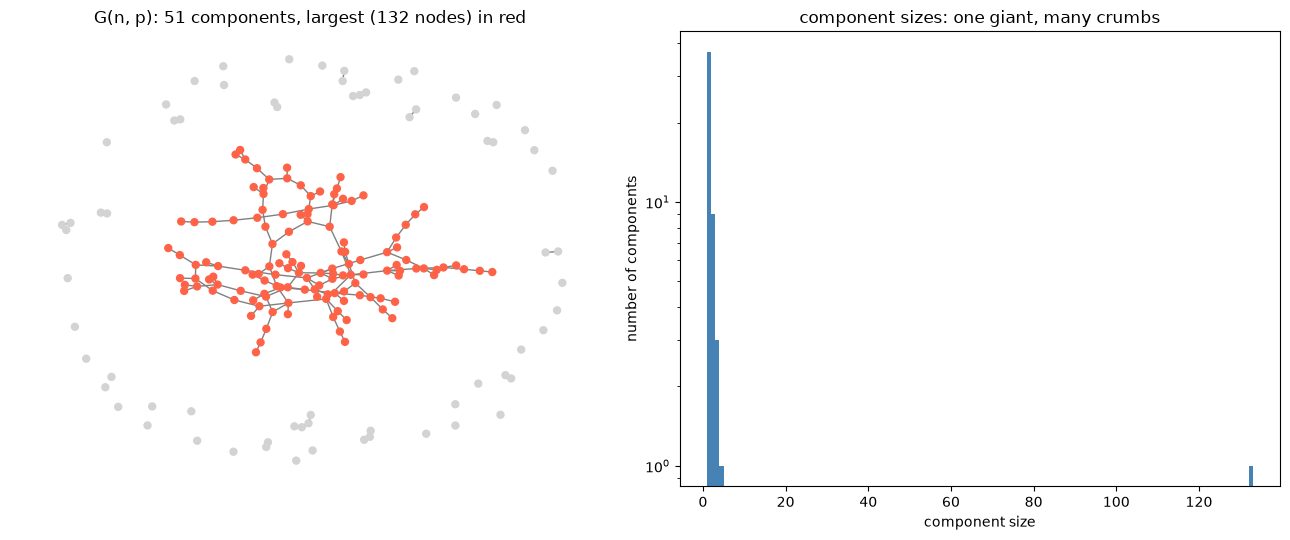

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
pos_er = nx.spring_layout(ER, seed=SEED)
in_largest = ["tomato" if v in components[0] else "lightgray" for v in ER.nodes()]
nx.draw_networkx(ER, pos=pos_er, ax=axes[0], node_size=25, with_labels=False, node_color=in_largest, edge_color="gray")
axes[0].set_title(f"G(n, p): {n_comp_er} components, largest ({size_largest_er} nodes) in red"); axes[0].axis("off")
sizes = [len(c) for c in components]
axes[1].hist(sizes, bins=range(1, max(sizes) + 2), color="steelblue")
axes[1].set_xlabel("component size"); axes[1].set_ylabel("number of components"); axes[1].set_yscale("log")
axes[1].set_title("component sizes: one giant, many crumbs")
plt.tight_layout(); plt.show()

## Part 3 (autograded): a few hubs, or everyone similar? degree distributions vs $G(n,p)$

**Why.** The board's third question is whether a few people hold the network together
or everyone is about the same. Part 1 already found one volunteer with 17 collaborators
against an average of about 4.6 — but 34 people is too few to read a *distribution*
off, so you need to know what the two signatures look like at scale. The lecture said
many real networks have **power-law-like** degree distributions: most nodes have few
neighbours, a few have very many. $G(n,p)$ does not — its degrees pile up around $np$.
The plot that shows the difference is the **CCDF on log–log axes**.

`BA` below is a **Barabási–Albert** graph: nodes arrive one at a time and each attaches
$m$ edges to existing nodes with probability proportional to their degree ("the rich get
richer" — the shape a volunteer network takes when new volunteers are steered toward
whoever is already busiest). It is the standard generator for heavy-tailed degrees. You
will build a $G(n,p)$ graph of the *same size and density* and compare; then look back
at the nonprofit's network and decide which of the two it resembles.

**Task.**

1. Set `p_match` so that a $G(n,p)$ graph with `N_BA` nodes has the same *expected*
   number of edges as `BA` (recall $p = e / \binom{n}{2}$), then build
   `ER2 = nx.erdos_renyi_graph(N_BA, p_match, seed=SEED)`.
2. Write `ccdf(degrees)`: given a 1-D array of degrees, return `(x, p)` where `x` is the
   sorted array of **unique** degree values and `p[k]` is the fraction of nodes with degree
   **at least** `x[k]` (the lecture's $P(X > x)$ curve; we use $\ge$ so the largest degree
   still appears on a log axis).
3. Set `deg_ba` and `deg_er` to the degree arrays of `BA` and `ER2`; `max_deg_ba`,
   `max_deg_er` (ints); and `frac_hubs_ba`, `frac_hubs_er`, the fraction of nodes whose
   degree exceeds **three times** the graph's mean degree.

Then run the plotting cell and *look*: on log–log axes one curve is roughly a straight
line and the other falls off a cliff.


In [13]:
N_BA = 1000
M_BA = 2
BA = nx.barabasi_albert_graph(N_BA, M_BA, seed=SEED)
print(f"BA: n = {N_BA}, m = {M_BA}, e = {BA.number_of_edges()}")

p_match = BA.number_of_edges() / (N_BA * (N_BA - 1) / 2)   # p = e / C(n, 2)
ER2 = nx.erdos_renyi_graph(N_BA, p_match, seed=SEED)

def ccdf(degrees):
    """Return (x, p): unique degree values and the fraction of nodes with degree >= x."""
    degrees = np.asarray(degrees)
    x = np.unique(degrees)                                # sorted unique degree values
    p = np.array([(degrees >= k).mean() for k in x])      # fraction of nodes with degree >= x
    return x, p

deg_ba = np.array([d for _, d in BA.degree()])
deg_er = np.array([d for _, d in ER2.degree()])
max_deg_ba, max_deg_er = int(deg_ba.max()), int(deg_er.max())
frac_hubs_ba = float((deg_ba > 3 * deg_ba.mean()).mean())
frac_hubs_er = float((deg_er > 3 * deg_er.mean()).mean())

print(f"p_match = {p_match:.5f}; ER2 has {ER2.number_of_edges()} edges")
print(f"BA : mean degree {deg_ba.mean():.2f}, max {max_deg_ba}, fraction of nodes above 3x mean: {frac_hubs_ba:.3f}")
print(f"ER2: mean degree {deg_er.mean():.2f}, max {max_deg_er}, fraction of nodes above 3x mean: {frac_hubs_er:.3f}")

BA: n = 1000, m = 2, e = 1996
p_match = 0.00400; ER2 has 2037 edges
BA : mean degree 3.99, max 78, fraction of nodes above 3x mean: 0.038
ER2: mean degree 4.07, max 12, fraction of nodes above 3x mean: 0.000


**Discuss (participation):** the board wants two things from its volunteer network:
an announcement should reach every volunteer within a couple of shifts, and the
organization should survive if its five busiest volunteers all leave at once. Both
synthetic networks have (almost) the same number of edges. For each goal, say which of
the two you would rather the nonprofit's network looked like — one sentence each,
using the word "hub".

- **Fast announcements:** the Barabási–Albert shape — its hubs (max degree 78 vs 12 in $G(n,p)$) act as broadcast points, so a message passed to a hub reaches a large share of volunteers within a couple of shifts.
- **Surviving the loss of the five busiest:** the $G(n,p)$ shape — it has no real hubs (no node above 3× the mean degree), so removing its top five barely changes connectivity, whereas removing the BA graph's five hubs cuts away a big chunk of its edges and can fragment the network.


In [14]:
grader.check("q3")

q3 results: All test cases passed!

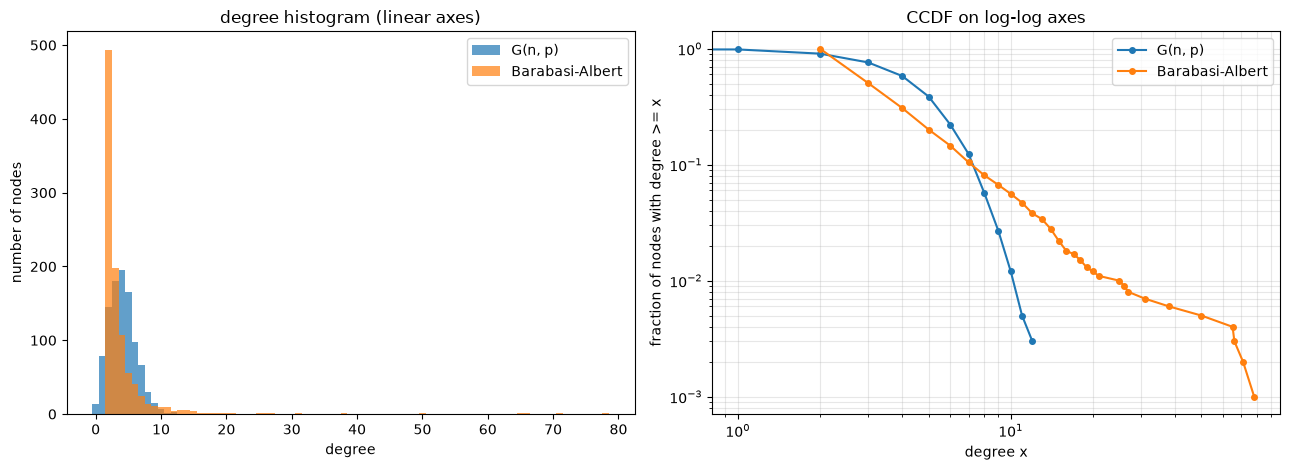

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
bins = np.arange(0, max(max_deg_ba, max_deg_er) + 2) - 0.5
axes[0].hist(deg_er, bins=bins, alpha=0.7, label="G(n, p)")
axes[0].hist(deg_ba, bins=bins, alpha=0.7, label="Barabasi-Albert")
axes[0].set_xlabel("degree"); axes[0].set_ylabel("number of nodes"); axes[0].legend(); axes[0].set_title("degree histogram (linear axes)")
for deg, label in [(deg_er, "G(n, p)"), (deg_ba, "Barabasi-Albert")]:
    x, p = ccdf(deg)
    axes[1].loglog(x, p, "o-", ms=4, label=label)
axes[1].set_xlabel("degree x"); axes[1].set_ylabel("fraction of nodes with degree >= x"); axes[1].legend()
axes[1].set_title("CCDF on log-log axes"); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

## Part 4 (autograded): do a volunteer's collaborators know each other? clustering — real vs random

**Why.** The board's last question is whether a volunteer's collaborators also work
with each other — whether shifts are run by tight crews or by people who rarely
overlap. That is the **clustering coefficient**: the probability that two of a node's
neighbours are themselves connected. NetworkX gives you both lecture definitions:
`nx.average_clustering(G)` is $C^{(2)}$ (mean of the per-node ratios) and
`nx.transitivity(G)` is $C^{(1)}$ (ratio of the sums, i.e. triangles over neighbour pairs).
For $G(n,p)$ both are $\approx p$, so a random network of the *same size and density*
is the baseline that tells you whether the crews are real.

**Task.**

1. `C_real = nx.average_clustering(G)`, `T_real = nx.transitivity(G)`.
2. `p_real`, the density of `G` ($e/\binom{n}{2}$); `R = nx.erdos_renyi_graph(n_nodes, p_real, seed=SEED)`;
   `C_rand = nx.average_clustering(R)`.
3. `clustering_ratio = C_real / C_rand`, and `c_top = nx.clustering(G, top_node)`, the local
   clustering coefficient of the top-degree node.


In [16]:
C_real = nx.average_clustering(G)
T_real = nx.transitivity(G)
p_real = n_edges / (n_nodes * (n_nodes - 1) / 2)   # density e / C(n, 2)
R = nx.erdos_renyi_graph(n_nodes, p_real, seed=SEED)
C_rand = nx.average_clustering(R)
clustering_ratio = C_real / C_rand
c_top = nx.clustering(G, top_node)

print(f"{REAL_NAME}: average clustering C2 = {C_real:.3f}, transitivity C1 = {T_real:.3f}")
print(f"G(n, p) with the same density (p = {p_real:.3f}): C = {C_rand:.3f}  ->  ratio {clustering_ratio:.1f}x")
print(f"local clustering of the top node {top_node!r}: {c_top:.3f}")

Zachary's karate club: average clustering C2 = 0.571, transitivity C1 = 0.256
G(n, p) with the same density (p = 0.139): C = 0.107  ->  ratio 5.3x
local clustering of the top node 33: 0.110


**Discuss (participation):** you will put one clustering number in the memo, and
$C^{(2)}$ (average clustering) and $C^{(1)}$ (transitivity) disagree on this network —
by a lot. Look at `c_top`: which kind of volunteer pulls the two apart, and which
definition weights that volunteer more? Then say which number you would report to the
board, and what question it answers.

The hubs pull the two apart: volunteer 33 has 17 collaborators but local clustering only 0.110 (and 0 has 16 with 0.15), and transitivity $C^{(1)}$ counts every neighbour *pair*, so a hub with $\binom{17}{2} = 136$ pairs weighs far more than a low-degree volunteer, dragging $C^{(1)}$ down to 0.256, while average clustering $C^{(2)}$ gives every volunteer one equal vote (11 of them sit in fully closed crews with $c = 1$) and lands at 0.571. I would report $C^{(2)} = 0.571$ (about 5× the 0.107 of a random network with the same density), because it answers the board's question about a typical volunteer: *how likely is it that two of my collaborators also work together?*


In [17]:
grader.check("q4")

q4 results: All test cases passed!

<!-- BEGIN QUESTION -->

## Report out: what you would tell the nonprofit

Write the two sentences you would put at the top of your memo to the nonprofit: the
recommendation, and the one caveat they must hear. Then pair-share with another team.

Discuss as a team first (~5 min), citing the cell that backs each claim:

1. **The answers they asked for.** One sentence each, with numbers from your notebook:
   one community or several (Part 2); a few hubs or everyone similar (Parts 1 and 3);
   do collaborators know each other (Part 4).
2. **Which network does the question need?** Parts 1–4 used the plain network: undirected,
   unweighted, an edge for any shared shift. The log also records *how often* (the weight
   column you dropped), and lecture 20 drew the same kind of data two other ways —
   **weighted** (the edge carries the shift count) and **directed** (an arrow from whoever
   organised the shift to whoever joined it). For each of the board's questions below,
   say which representation you would use and what would change if you switched:
   - *"Who is socially closest to whom?"* — would the ranking of 33's collaborators,
     all at one hop in the plain network, change if the shift counts counted?
   - *"Would an announcement reach everyone?"* — does any shared shift suffice, or only
     frequent ones?
   - *"Who holds the network together?"* — what would the log have to record before a
     directed version is honest, and what does symmetrising a one-way relation assume?
   - A colleague proposes a fourth network from the volunteer *survey* (skills,
     availability): connect any two volunteers whose answers are "close enough". What
     must they report alongside any component count from such a network?
3. **Your takeaway.** What is the one thing this study taught you — about networks,
   about baselines, or about turning a graph into advice someone will act on — that
   you would want the rest of the class to hear?

**Pair-share (~3 min).** Turn to a neighboring team and compare memos: did you make the
same recommendation and name the same caveat? If not, whose evidence is stronger? Be
ready to share one takeaway with the class.

> Staff will visit tables during this part. Be ready to explain your reasoning and to
> point at the cell that supports each claim.


_Type your answer here, replacing this text._

<!-- END QUESTION -->

## Wrap-up

Before you leave, each group should be able to answer, without notes:

1. Why is degree a row sum of the adjacency matrix, and what does a symmetric $A$ tell you?
2. What did the $G(n,p)$ graph of the same density do differently from the nonprofit's
   network — in components, in degree distribution, in clustering?
3. Which of the nonprofit's questions would the weighted version of the same log answer
   differently from the plain one, and which would it not?

Submit the autograded parts (1–4) to Gradescope.
